In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

In [13]:
wine = pd.read_csv("wine_clean.csv")

In [14]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  kind                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [15]:
wine.head(4)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,kind
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


In [16]:
selected_cols = ["alcohol","total sulfur dioxide"]

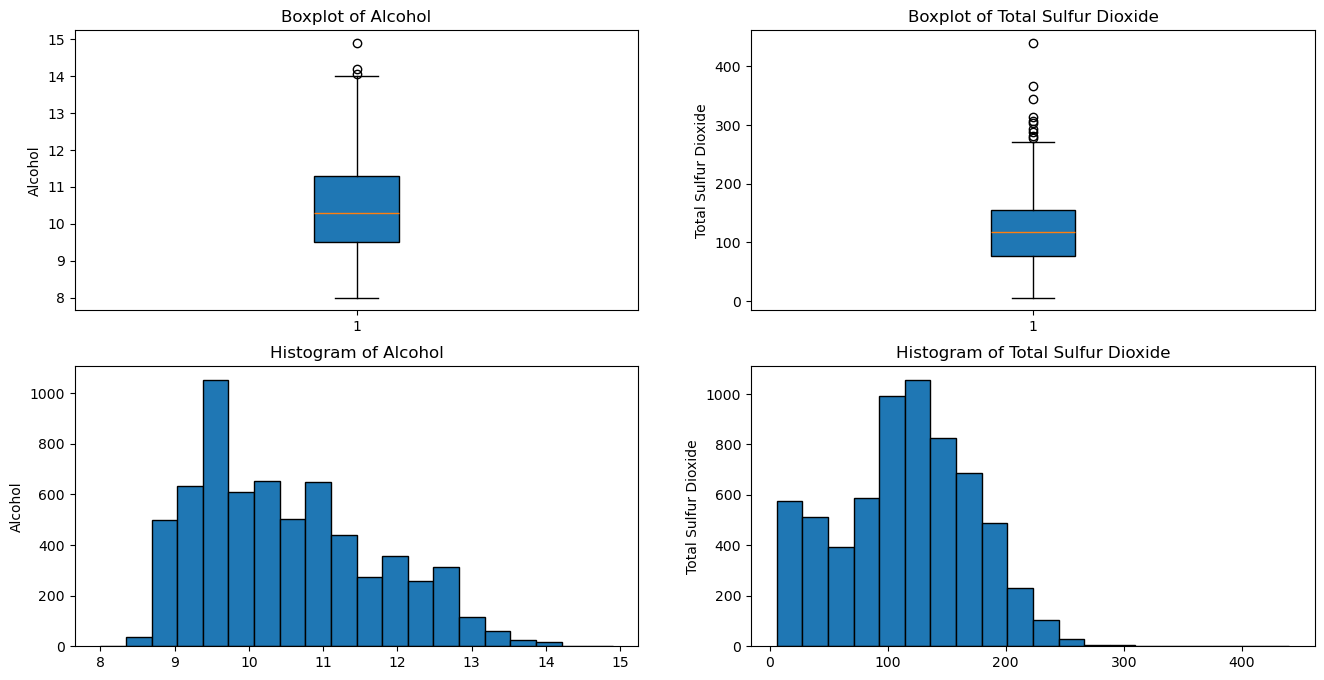

In [17]:
def draw_plots():
    # Create boxplots to identify outliers
    plt.figure(figsize=(16, 8))
    
    plt.subplot(2, 2, 1)
    plt.boxplot(wine['alcohol'], patch_artist=True)
    plt.title('Boxplot of Alcohol')
    plt.ylabel('Alcohol')
    
    plt.subplot(2, 2, 2)
    plt.boxplot(wine['total sulfur dioxide'], patch_artist=True)
    plt.title('Boxplot of Total Sulfur Dioxide')
    plt.ylabel('Total Sulfur Dioxide')

    plt.subplot(2, 2, 3)
    plt.hist(wine['alcohol'], bins=20, edgecolor='black')
    plt.title('Histogram of Alcohol')
    plt.ylabel('Alcohol')
    
    
    plt.subplot(2, 2, 4)
    plt.hist(wine['total sulfur dioxide'], bins=20, edgecolor='black')
    plt.title('Histogram of Total Sulfur Dioxide')
    plt.ylabel('Total Sulfur Dioxide')

draw_plots()

# fix outliers first 

In [18]:
for col in selected_cols:
    print("")
    print(f"Column Name:{col}")
    median_val = wine[col].median() 
    print(f"median: {median_val}")
    
    #caluclate 25th percentile of leaf length
    percentile25 = wine[col].quantile(0.25)
    print(f"percentile25: {percentile25}")

    #caluclate 75th percentile of leaf length
    percentile75 = wine[col].quantile(0.75)
    print(f"percentile75: {percentile75}")
    
    #Calculate interquartile range
    iqr = percentile75 - percentile25
    print(f"iqr: {iqr}")

    #calcualte upper and lower thresholds for outliers
    upper_limit = percentile75 + 1.5 *iqr
    lower_limit = percentile25 - 1.5 * iqr
    
    df_lower = wine[wine[col] < lower_limit]
    outliers_lower = df_lower[col].tolist()
    wine[col] = wine[col].replace(outliers_lower, median_val)
    print(f"outliers_lower: {outliers_lower}")
    
    df_higher = wine[wine[col] > upper_limit]
    outliers_higher = df_higher[col].tolist()
    wine[col] = wine[col].replace(outliers_higher, median_val)
    print(f"outliers_higher: {outliers_higher}")



Column Name:alcohol
median: 10.3
percentile25: 9.5
percentile75: 11.3
iqr: 1.8000000000000007
outliers_lower: []
outliers_higher: [14.2, 14.05, 14.9]

Column Name:total sulfur dioxide
median: 118.0
percentile25: 77.0
percentile75: 156.0
iqr: 79.0
outliers_lower: []
outliers_higher: [313.0, 366.5, 307.5, 344.0, 282.0, 303.0, 294.0, 440.0, 278.0, 289.0]


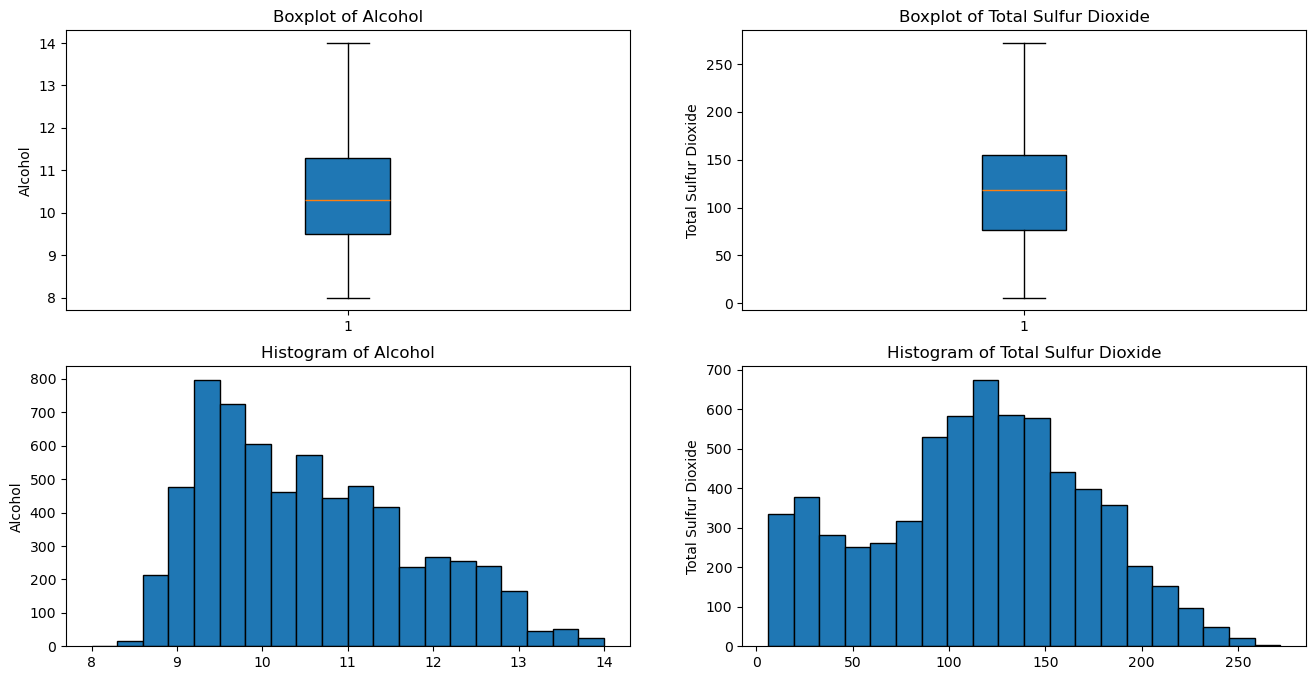

In [19]:
#check if skewness is fixed by removing outlierrs
draw_plots()

In [22]:
print(f"{selected_cols[0]} skewness: {wine[selected_cols[0]].skew()}")
print(f"{selected_cols[1]} skewness: {wine[selected_cols[1]].skew()}")

alcohol skewness: 0.5580855009127813
total sulfur dioxide skewness: -0.07494466296906824


In [35]:
# Since fixing the outliers did not reduce the skewness, we will apply a transformations.

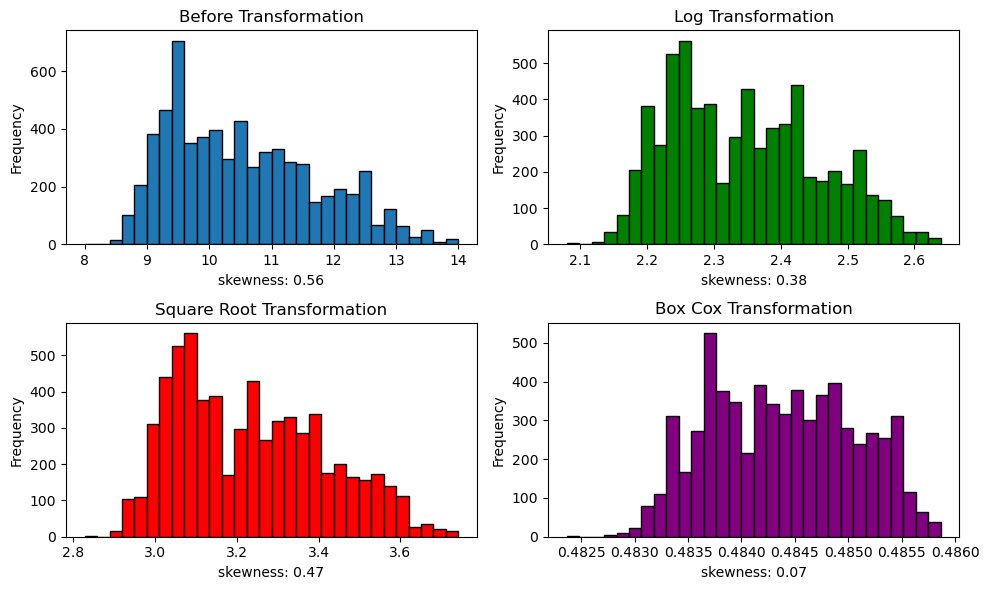

In [36]:
# Applying log transformation to fix skewness

wine['alcohol_log'] = np.log(wine['alcohol'])
wine['alcohol_sqrt'] = np.sqrt(wine['alcohol'])
wine['alcohol_boxcox'], _ = stats.boxcox(wine['alcohol'] + 1)  # Adding 1 to handle zero values

# Displaying histogram after transformation
plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.hist(wine['alcohol'], bins=30, edgecolor='black')
plt.title('Before Transformation')
plt.xlabel(f"skewness: {wine['alcohol'].skew():.2f}")
plt.ylabel('Frequency')

plt.subplot(2, 2, 2)
plt.hist(wine['alcohol_log'], bins=30, color='green', edgecolor='black')
plt.title('Log Transformation')
plt.xlabel(f"skewness: {wine['alcohol_log'].skew():.2f}")
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.hist(wine['alcohol_sqrt'], bins=30, color='red', edgecolor='black')
plt.title('Square Root Transformation')
plt.xlabel(f"skewness: {wine['alcohol_sqrt'].skew():.2f}")
plt.ylabel('Frequency')

plt.subplot(2, 2, 4)
plt.hist(wine['alcohol_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Box Cox Transformation')
plt.xlabel(f"skewness: {wine['alcohol_boxcox'].skew():.2f}")
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# we notice that boxcos has fixed the issues for Alcohol, therefore, we use this for the statistcal analysis

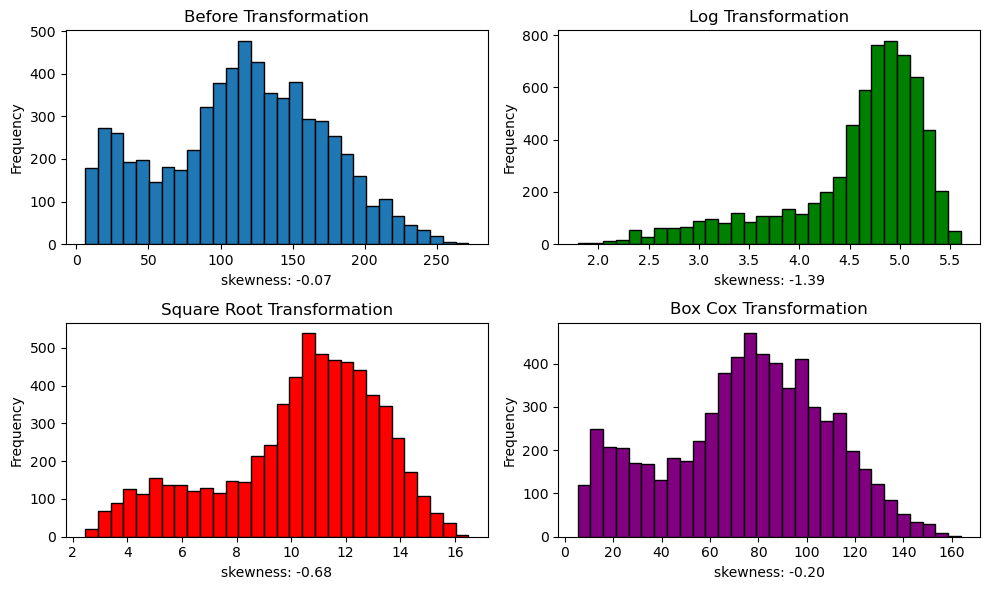

In [37]:
# Applying log transformation to fix skewness

wine['tsd_log'] = np.log(wine['total sulfur dioxide'])
wine['tsd_sqrt'] = np.sqrt(wine['total sulfur dioxide'])
wine['tsd_boxcox'], _ = stats.boxcox(wine['total sulfur dioxide'] + 1)  # Adding 1 to handle zero values

# Displaying histogram after transformation
plt.figure(figsize=(10, 6))

plt.subplot(2, 2, 1)
plt.hist(wine['total sulfur dioxide'], bins=30, edgecolor='black')
plt.title('Before Transformation')
plt.xlabel(f"skewness: {wine['total sulfur dioxide'].skew():.2f}")
plt.ylabel('Frequency')

plt.subplot(2, 2, 2)
plt.hist(wine['tsd_log'], bins=30, color='green', edgecolor='black')
plt.title('Log Transformation')
plt.xlabel(f"skewness: {wine['tsd_log'].skew():.2f}")
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)
plt.hist(wine['tsd_sqrt'], bins=30, color='red', edgecolor='black')
plt.title('Square Root Transformation')
plt.xlabel(f"skewness: {wine['tsd_sqrt'].skew():.2f}")
plt.ylabel('Frequency')

plt.subplot(2, 2, 4)
plt.hist(wine['tsd_boxcox'], bins=30, color='purple', edgecolor='black')
plt.title('Box Cox Transformation')
plt.xlabel(f"skewness: {wine['tsd_boxcox'].skew():.2f}")
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()